In [1]:
#Montar drive
from google.colab import drive
!pip install linearmodels -q
import os
import unicodedata
import numpy as np
import pandas as pd

from linearmodels.panel import PanelOLS, RandomEffects, compare

drive.mount("/content/drive")
RUTA_PANEL = "/content/drive/MyDrive/Tesis_caso/panel_ecobici.csv"
CARPETA_FIGS = "/content/drive/MyDrive/Tesis_caso/figuras_eda"

panel = pd.read_csv(RUTA_PANEL)
# Por si algún día el CSV se guarda con índice: quita la columna "Unnamed: 0"
panel = panel.loc[:, ~panel.columns.str.startswith("Unnamed")]

# Variables que usan los modelos (antes se creaban en Experimento.ipynb)
panel["log_viajes"] = np.log1p(panel["n_viajes"])
panel["log_inversion"] = np.log(panel["inversion_publica"])
print(panel.shape, list(panel.columns))

Mounted at /content/drive
(345, 11) ['anio', 'trimestre', 'alcaldia_norm', 'genero', 'n_viajes', 'estaciones_activas', 'inseguro_pct', 'seguro_pct', 'inversion_publica', 'log_viajes', 'log_inversion']


#Análisis exploratorio de datos

In [2]:
# =============================================================================
# ANÁLISIS EXPLORATORIO DEL PANEL ECOBICI x ENSU x INVERSIÓN (FORMATO IEEE)
# =============================================================================
# Mismas 5 gráficas del EDA, adaptadas a IEEE:
#   - Ancho de dos columnas (7.16 in) o de una (3.5 in).
#   - Letra con serifa tipo Times, 7-8 pt.
#   - Blanco y negro: se distingue por marcador, tipo de línea y trama.
#   - Sin títulos dentro de la figura: el título va en el pie, en Word.
#     Los paneles se marcan (a), (b), (c) para citarlos en el pie.
#   - Se guarda en PNG 600 dpi (para Word), PDF con fuentes incrustadas y SVG.
#
#   G1. Distribución de viajes y peso de cada género
#   G2. Viajes por alcaldía en el tiempo
#   G3. ENSU: nivel y saltos trimestrales
#   G4. Variación entre alcaldías vs. dentro de cada alcaldía
#   G5. Estaciones activas contra viajes
# =============================================================================


# [Celda 1] Librerías, rutas y estilo IEEE --------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


os.makedirs(CARPETA_FIGS, exist_ok=True)

ANCHO_1COL = 3.5    # pulgadas
ANCHO_2COL = 7.16   # pulgadas

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "lines.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "hatch.linewidth": 0.5,
    "pdf.fonttype": 42,   # fuentes incrustadas (IEEE PDF eXpress)
    "ps.fonttype": 42,
    "savefig.dpi": 600,
    "figure.dpi": 150,
})

NOMBRES = {
    "ALVARO OBREGON": "Álvaro Obregón", "AZCAPOTZALCO": "Azcapotzalco",
    "BENITO JUAREZ": "Benito Juárez", "COYOACAN": "Coyoacán",
    "CUAUHTEMOC": "Cuauhtémoc", "MIGUEL HIDALGO": "Miguel Hidalgo",
}
# Cada alcaldía con su marcador y tipo de línea (se distinguen sin color)
ESTILO_ALC = {
    "CUAUHTEMOC":     dict(marker="o", linestyle="-"),
    "MIGUEL HIDALGO": dict(marker="s", linestyle="--"),
    "BENITO JUAREZ":  dict(marker="^", linestyle="-."),
    "COYOACAN":       dict(marker="D", linestyle=":"),
    "ALVARO OBREGON": dict(marker="v", linestyle=(0, (5, 1, 1, 1))),
    "AZCAPOTZALCO":   dict(marker="P", linestyle=(0, (1, 1))),
}
# Género: tono de gris, trama y tipo de línea
ESTILO_GEN = {
    "F": dict(gris="0.25", trama="",     linea="-"),
    "M": dict(gris="0.65", trama="",     linea="--"),
    "O": dict(gris="0.85", trama="////", linea="-."),
    "?": dict(gris="1.0",  trama="....", linea=":"),
}
ETIQ_GEN = {"F": "Mujeres (F)", "M": "Hombres (M)", "O": "Otro (O)",
            "?": "Sin dato (?)"}


def guardar(fig, nombre):
    for ext in ("png", "pdf", "svg"):
        fig.savefig(os.path.join(CARPETA_FIGS, f"{nombre}.{ext}"),
                    bbox_inches="tight", pad_inches=0.02)
    print(f"Guardada: {os.path.join(CARPETA_FIGS, nombre)}.png/.pdf/.svg")


def marca_panel(ax, letra):
    """Etiqueta (a), (b)... arriba a la izquierda, para citarla en el pie."""
    ax.set_title(f"({letra})", loc="left", pad=3)


def linea_alc(ax, x, y, alc, **extra):
    ax.plot(x, y, color="black", markersize=3, markerfacecolor="white",
            markeredgewidth=0.6, linewidth=0.8, label=NOMBRES.get(alc, alc),
            **ESTILO_ALC[alc], **extra)



In [3]:

# [Celda 2] Carga y variables auxiliares ----------------------------------
panel = pd.read_csv(RUTA_PANEL)
panel = panel.loc[:, ~panel.columns.str.startswith("Unnamed")]
panel["periodo"] = panel["anio"] * 4 + panel["trimestre"]
panel["etiqueta"] = panel["anio"].astype(str) + "-T" + panel["trimestre"].astype(str)
panel["log_viajes"] = np.log1p(panel["n_viajes"])

pa = (panel.groupby(["anio", "trimestre", "periodo", "etiqueta", "alcaldia_norm"],
                    as_index=False)
      .agg(n_viajes=("n_viajes", "sum"),
           estaciones_activas=("estaciones_activas", "first"),
           inseguro_pct=("inseguro_pct", "first"),
           inversion_publica=("inversion_publica", "first")))
pa["log_viajes"] = np.log1p(pa["n_viajes"])

PERIODOS = sorted(pa["periodo"].unique())
ETIQ_PER = dict(zip(pa["periodo"], pa["etiqueta"]))
ORDEN = (pa.groupby("alcaldia_norm")["periodo"].min()
         .sort_values(kind="stable").index.tolist())

print(f"Panel por género: {len(panel)} filas | agregado: {len(pa)} filas")
print("Trimestres sin ENSU:", sorted(pa.loc[pa["inseguro_pct"].isna(), "etiqueta"].unique()))
print("Trimestres sin inversión:",
      sorted(pa.loc[pa["inversion_publica"].isna(), "etiqueta"].unique()))


def ejes_tiempo(ax, paso=2):
    ticks = PERIODOS[::paso]
    ax.set_xticks(ticks)
    ax.set_xticklabels([ETIQ_PER[p] for p in ticks], rotation=90)


def leyenda_alcaldias(fig, y=1.04):
    """Una sola leyenda arriba de la figura, en un renglón."""
    h, l = fig.axes[0].get_legend_handles_labels()
    fig.legend(h, l, ncol=6, frameon=False, loc="lower center",
               bbox_to_anchor=(0.5, y), handlelength=2.8, columnspacing=1.2)



Panel por género: 345 filas | agregado: 105 filas
Trimestres sin ENSU: []
Trimestres sin inversión: ['2026-T1']


Guardada: /content/drive/MyDrive/Tesis_caso/figuras_eda/eda1_distribucion_genero.png/.pdf/.svg


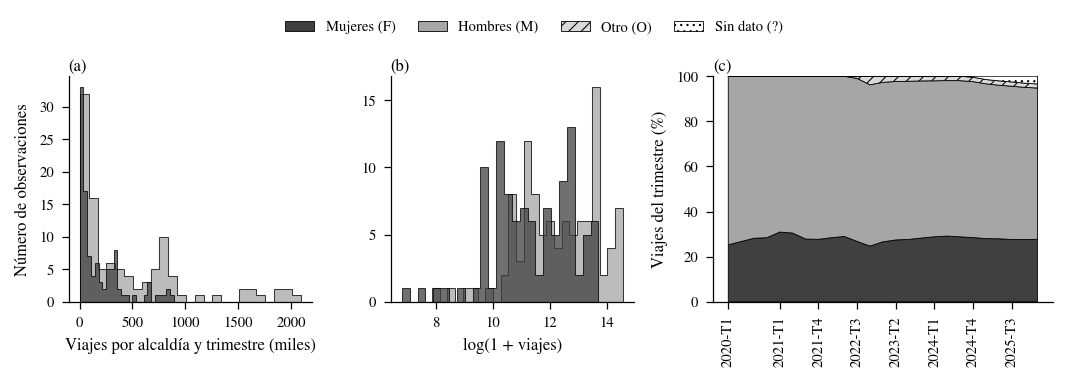

Participación promedio por género (%):
genero
F    28.0
M    70.2
O     1.3
?     0.5


In [4]:

# [Celda 3] G1. Distribución de viajes y peso de cada género --------------
# (a) nivel y (b) log(1+viajes), solo mujeres y hombres (O y ? pesan menos
# de 2 % y se ven en el panel c). (c) composición por género en el tiempo.
# Mismo relleno por género en los tres paneles.
fig, axes = plt.subplots(1, 3, figsize=(ANCHO_2COL, 2.3),
                         gridspec_kw={"width_ratios": [1, 1, 1.4]})
for g in ["M", "F"]:   # hombres atrás, mujeres encima
    sub = panel[panel["genero"] == g]
    e = ESTILO_GEN[g]
    opciones = dict(bins=25, histtype="stepfilled", facecolor=e["gris"],
                    edgecolor="black", linewidth=0.5, alpha=0.75)
    axes[0].hist(sub["n_viajes"] / 1e3, **opciones)
    axes[1].hist(sub["log_viajes"], **opciones)
axes[0].set_xlabel("Viajes por alcaldía y trimestre (miles)")
axes[0].set_ylabel("Número de observaciones")
axes[1].set_xlabel("log(1 + viajes)")
axes[1].yaxis.get_major_locator().set_params(integer=True)

comp = panel.pivot_table(index="periodo", columns="genero", values="n_viajes",
                         aggfunc="sum").fillna(0)
comp = comp.div(comp.sum(axis=1), axis=0) * 100
comp = comp[[g for g in ["F", "M", "O", "?"] if g in comp.columns]]
capas = axes[2].stackplot(comp.index, comp.T.values,
                          colors=[ESTILO_GEN[g]["gris"] for g in comp.columns],
                          edgecolor="black", linewidth=0.4)
for capa, g in zip(capas, comp.columns):
    capa.set_hatch(ESTILO_GEN[g]["trama"])
axes[2].set_ylim(0, 100)
axes[2].set_ylabel("Viajes del trimestre (%)")
ejes_tiempo(axes[2], paso=3)

for ax, letra in zip(axes, "abc"):
    marca_panel(ax, letra)

# Leyenda común con el relleno de cada género
from matplotlib.patches import Patch
manijas = [Patch(facecolor=ESTILO_GEN[g]["gris"], hatch=ESTILO_GEN[g]["trama"],
                 edgecolor="black", linewidth=0.4) for g in comp.columns]
fig.legend(manijas, [ETIQ_GEN[g] for g in comp.columns], ncol=4, frameon=False,
           loc="lower center", bbox_to_anchor=(0.5, 0.98), columnspacing=1.5)
fig.tight_layout()
guardar(fig, "eda1_distribucion_genero")
plt.show()

print("Participación promedio por género (%):")
print(comp.mean().round(1).to_string())



Guardada: /content/drive/MyDrive/Tesis_caso/figuras_eda/eda2_viajes_por_alcaldia.png/.pdf/.svg


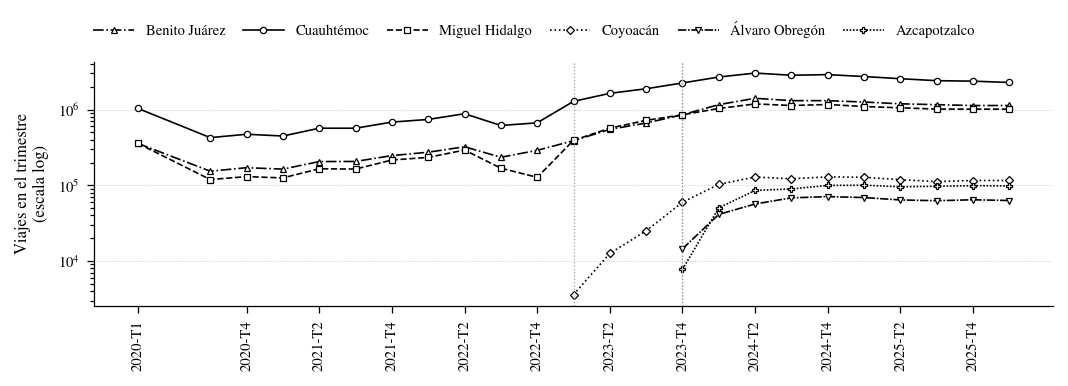

In [5]:
# [Celda 4] G2. Viajes por alcaldía en el tiempo --------------------------
# Escala log. Las líneas verticales marcan el primer trimestre de las
# alcaldías que entran después (ver N-5).
fig, ax = plt.subplots(figsize=(ANCHO_2COL, 2.3))
inicio = pa["periodo"].min()
for alc in ORDEN:
    sub = pa[pa["alcaldia_norm"] == alc].sort_values("periodo")
    linea_alc(ax, sub["periodo"], sub["n_viajes"], alc)
    p0 = sub["periodo"].min()
    if p0 > inicio:
        ax.axvline(p0, color="0.6", linestyle=":", linewidth=0.6)
ax.set_yscale("log")
ax.set_ylabel("Viajes en el trimestre\n(escala log)")
ejes_tiempo(ax)
ax.grid(axis="y", linestyle=":", linewidth=0.4, color="0.75")
leyenda_alcaldias(fig, y=0.98)
fig.tight_layout()
guardar(fig, "eda2_viajes_por_alcaldia")
plt.show()

Guardada: /content/drive/MyDrive/Tesis_caso/figuras_eda/eda3_ensu_nivel_y_saltos.png/.pdf/.svg


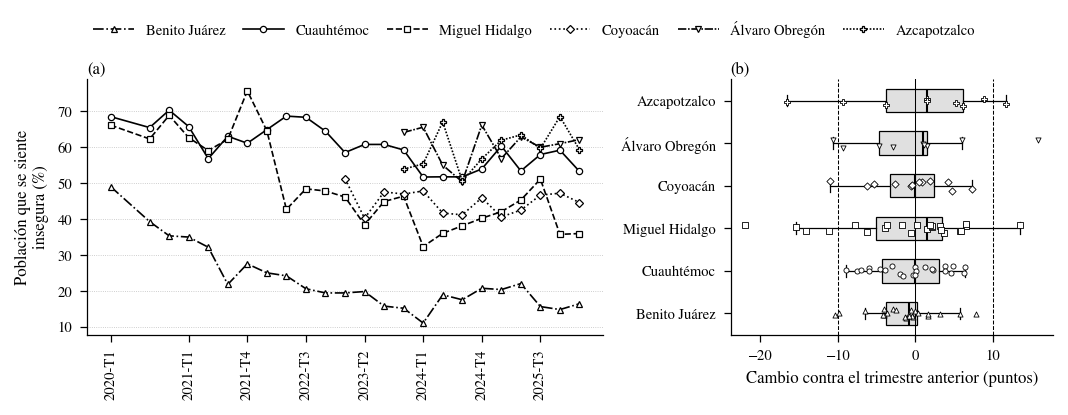

Saltos trimestrales en puntos, por alcaldía:
                desv_est  max_abs  saltos_mayores_10
alcaldia_norm                                       
BENITO JUAREZ        4.2     10.3                  1
CUAUHTEMOC           4.6      8.9                  0
MIGUEL HIDALGO       8.3     21.9                  5
COYOACAN             5.1     11.0                  1
ALVARO OBREGON       8.0     15.8                  2
AZCAPOTZALCO         9.0     16.4                  2


In [6]:
#  [Celda 5] G3. ENSU: nivel y saltos trimestrales -------------------------
# (a) % de población insegura por alcaldía. (b) cambio contra el trimestre
# anterior, en puntos; líneas punteadas en ±10 puntos (SN-2, punto 2).
ensu = pa.dropna(subset=["inseguro_pct"]).sort_values(["alcaldia_norm", "periodo"])
ensu["cambio_pp"] = ensu.groupby("alcaldia_norm")["inseguro_pct"].diff()

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_2COL, 2.5),
                         gridspec_kw={"width_ratios": [1.6, 1]})
for alc in ORDEN:
    sub = ensu[ensu["alcaldia_norm"] == alc]
    linea_alc(axes[0], sub["periodo"], sub["inseguro_pct"], alc)
axes[0].set_ylabel("Población que se siente\ninsegura (%)")
ejes_tiempo(axes[0], paso=3)
axes[0].grid(axis="y", linestyle=":", linewidth=0.4, color="0.75")

datos_box = [ensu.loc[ensu["alcaldia_norm"] == a, "cambio_pp"].dropna() for a in ORDEN]
bp = axes[1].boxplot(datos_box, vert=False, patch_artist=True, widths=0.55,
                     showfliers=False)
for caja in bp["boxes"]:
    caja.set(facecolor="0.88", edgecolor="black", linewidth=0.6)
for parte in ("whiskers", "caps"):
    for l in bp[parte]:
        l.set(color="black", linewidth=0.6)
for l in bp["medians"]:
    l.set(color="black", linewidth=1.0)
rng = np.random.default_rng(1)
for i, (d, alc) in enumerate(zip(datos_box, ORDEN), start=1):
    axes[1].scatter(d, i + rng.uniform(-0.12, 0.12, len(d)), s=6,
                    marker=ESTILO_ALC[alc]["marker"], facecolors="white",
                    edgecolors="black", linewidths=0.4, zorder=3)
axes[1].set_yticks(range(1, len(ORDEN) + 1))
axes[1].set_yticklabels([NOMBRES[a] for a in ORDEN])
axes[1].axvline(0, color="black", linewidth=0.5)
for v in (-10, 10):
    axes[1].axvline(v, color="black", linestyle="--", linewidth=0.5)
axes[1].set_xlabel("Cambio contra el trimestre anterior (puntos)")

for ax, letra in zip(axes, "ab"):
    marca_panel(ax, letra)
leyenda_alcaldias(fig, y=0.98)
fig.tight_layout()
guardar(fig, "eda3_ensu_nivel_y_saltos")
plt.show()

print("Saltos trimestrales en puntos, por alcaldía:")
print(ensu.groupby("alcaldia_norm")["cambio_pp"]
      .agg(desv_est="std", max_abs=lambda s: s.abs().max(),
           saltos_mayores_10=lambda s: (s.abs() > 10).sum())
      .round(1).loc[ORDEN].to_string())


Guardada: /content/drive/MyDrive/Tesis_caso/figuras_eda/eda4_variacion_within.png/.pdf/.svg


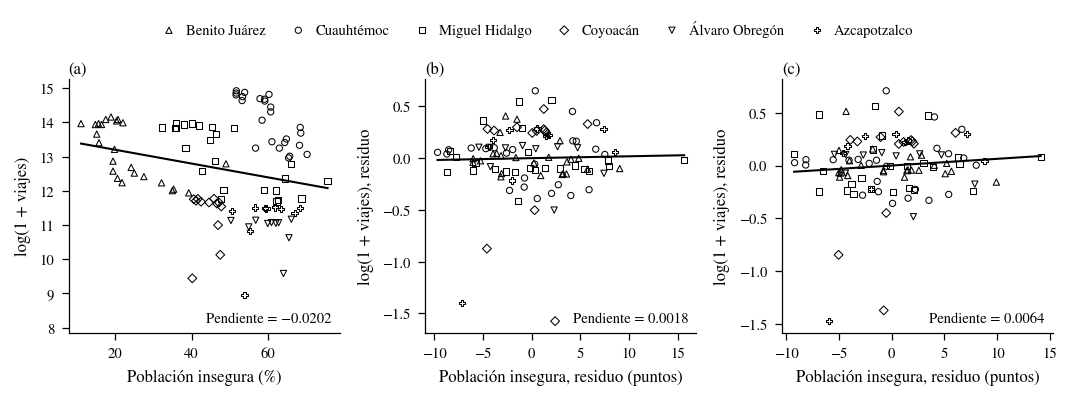

Desv. est. de % inseguro: cruda 16.5 pp; tras efectos fijos 4.7 pp (8.1 % de la varianza)


In [7]:
# [Celda 6] G4. Variación entre alcaldías vs. dentro de cada alcaldía -----
# (a) datos crudos; (b) quitando efectos de alcaldía y de trimestre;
# (c) quitando además estaciones activas (= Ejercicio 1). Descriptiva.
def residualizar(df, cols, controles=()):
    X = pd.get_dummies(df["alcaldia_norm"].astype(str), prefix="a")
    X = pd.concat([X, pd.get_dummies(df["periodo"].astype(str), prefix="t",
                                     drop_first=True)], axis=1)
    for c in controles:
        X[c] = df[c]
    X = X.astype(float).values
    res = {}
    for c in cols:
        y = df[c].astype(float).values
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        res[c] = y - X @ beta
    return pd.DataFrame(res, index=df.index)


base = pa.dropna(subset=["inseguro_pct", "log_viajes"]).copy()
r1 = residualizar(base, ["inseguro_pct", "log_viajes"])
r2 = residualizar(base, ["inseguro_pct", "log_viajes"], controles=["estaciones_activas"])
base["inseg_res"], base["logv_res"] = r1["inseguro_pct"], r1["log_viajes"]
base["inseg_res_e"], base["logv_res_e"] = r2["inseguro_pct"], r2["log_viajes"]

fig, axes = plt.subplots(1, 3, figsize=(ANCHO_2COL, 2.4))
paneles = [
    ("inseguro_pct", "log_viajes", "Población insegura (%)", "log(1 + viajes)"),
    ("inseg_res", "logv_res", "Población insegura, residuo (puntos)", "log(1 + viajes), residuo"),
    ("inseg_res_e", "logv_res_e", "Población insegura, residuo (puntos)", "log(1 + viajes), residuo"),
]
for ax, letra, (cx, cy, xl, yl) in zip(axes, "abc", paneles):
    for alc in ORDEN:
        sub = base[base["alcaldia_norm"] == alc]
        ax.scatter(sub[cx], sub[cy], s=9, marker=ESTILO_ALC[alc]["marker"],
                   facecolors="none", edgecolors="black", linewidths=0.5,
                   label=NOMBRES[alc])
    pend, inter = np.polyfit(base[cx], base[cy], 1)
    xs = np.linspace(base[cx].min(), base[cx].max(), 50)
    ax.plot(xs, inter + pend * xs, color="black", linewidth=1.0)
    ax.text(0.97, 0.04, f"Pendiente = {pend:.4f}".replace("-", "−"),
            transform=ax.transAxes, ha="right", fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.0), zorder=5)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    marca_panel(ax, letra)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, ncol=6, frameon=False, loc="lower center",
           bbox_to_anchor=(0.5, 0.98), columnspacing=1.2, handletextpad=0.2)
fig.tight_layout()
guardar(fig, "eda4_variacion_within")
plt.show()

var_total, var_within = base["inseguro_pct"].var(), base["inseg_res"].var()
print(f"Desv. est. de % inseguro: cruda {np.sqrt(var_total):.1f} pp; "
      f"tras efectos fijos {np.sqrt(var_within):.1f} pp "
      f"({100 * var_within / var_total:.1f} % de la varianza)")



Guardada: /content/drive/MyDrive/Tesis_caso/figuras_eda/eda5_estaciones_vs_viajes.png/.pdf/.svg


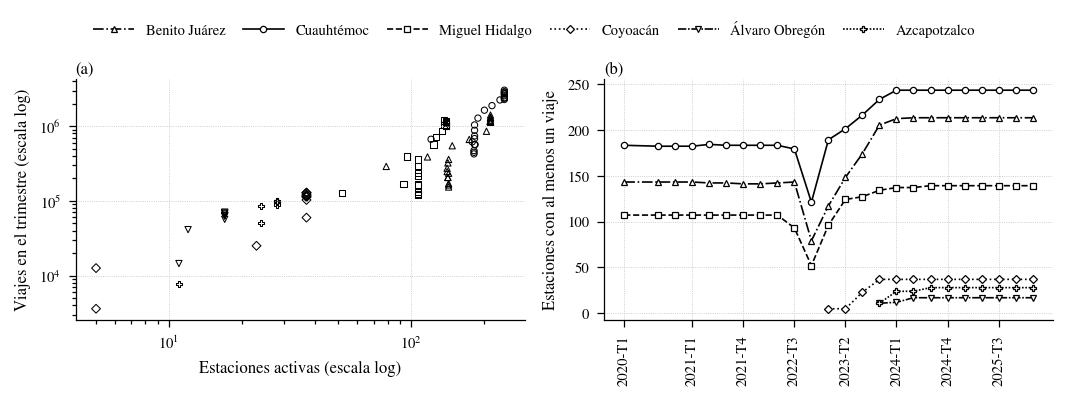

Correlación dentro de cada alcaldía, log(estaciones) vs log(viajes):
alcaldia_norm
BENITO JUAREZ     0.80
CUAUHTEMOC        0.83
MIGUEL HIDALGO    0.77
COYOACAN          0.94
ALVARO OBREGON    0.91
AZCAPOTZALCO      0.99


In [8]:
# [Celda 7] G5. Estaciones activas contra viajes --------------------------
# (a) viajes contra estaciones activas, escala log; (b) estaciones activas en
# el tiempo. "Estaciones activas" se cuenta con estaciones que tuvieron
# viajes, así que depende del propio resultado (SN-2, punto 5).
fig, axes = plt.subplots(1, 2, figsize=(ANCHO_2COL, 2.4))
for alc in ORDEN:
    sub = pa[pa["alcaldia_norm"] == alc].sort_values("periodo")
    axes[0].scatter(sub["estaciones_activas"], sub["n_viajes"], s=9,
                    marker=ESTILO_ALC[alc]["marker"], facecolors="none",
                    edgecolors="black", linewidths=0.5, label=NOMBRES[alc])
    linea_alc(axes[1], sub["periodo"], sub["estaciones_activas"], alc)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Estaciones activas (escala log)")
axes[0].set_ylabel("Viajes en el trimestre (escala log)")
axes[1].set_ylabel("Estaciones con al menos un viaje")
ejes_tiempo(axes[1], paso=3)
for ax, letra in zip(axes, "ab"):
    marca_panel(ax, letra)
    ax.grid(linestyle=":", linewidth=0.4, color="0.75")
h, l = axes[1].get_legend_handles_labels()
fig.legend(h, l, ncol=6, frameon=False, loc="lower center",
           bbox_to_anchor=(0.5, 0.98), handlelength=2.8, columnspacing=1.2)
fig.tight_layout()
guardar(fig, "eda5_estaciones_vs_viajes")
plt.show()

print("Correlación dentro de cada alcaldía, log(estaciones) vs log(viajes):")
print(pa.assign(log_est=np.log(pa["estaciones_activas"]))
      .groupby("alcaldia_norm")[["log_est", "log_viajes"]]
      .apply(lambda d: d["log_est"].corr(d["log_viajes"]))
      .round(2).loc[ORDEN].to_string())

#Modelo

In [9]:
# -----------------------------------------------------------------------
# PASO 6. Modelo de efectos fijos (dos vías) con errores agrupados por
#          alcaldía. Única función de estimación del notebook.
# -----------------------------------------------------------------------
def correr_modelo_fe(df, variables_independientes, nombre_modelo=None,
                     y="log_viajes"):
    d = df.copy()
    if "periodo" not in d.columns:
        d["periodo"] = d["anio"].astype(int) * 4 + d["trimestre"].astype(int)
    d = (d.dropna(subset=[y] + variables_independientes)
           .set_index(["alcaldia_norm", "periodo"]))

    modelo = PanelOLS(d[y], d[variables_independientes],
                      entity_effects=True, time_effects=True, drop_absorbed=True)
    res = modelo.fit(cov_type="clustered", cluster_entity=True)
    res.n_grupos = d.index.get_level_values(0).nunique()   # lo usa resumen()

    if nombre_modelo:   # solo imprime el resumen completo si le das nombre
        print(f"\n{'='*80}\n{nombre_modelo}\n{'='*80}")
        print(res)
    return res

Diseño del modelo
Importante: Se toma el % de percepción inseguridad como variable independiente.
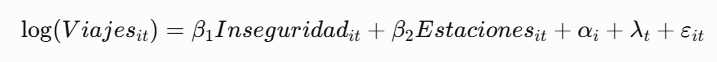



**Hipótesis teórica:** se espera que un aumento en la percepción de inseguridad se asocie con una disminución en el uso de ECOBICI, es decir:

$$
\beta_1 < 0
$$

**Hipótesis estadística contrastada:**

$$
H_0: \beta_1 = 0 \qquad \text{frente a} \qquad H_1: \beta_1 \neq 0
$$

donde $H_0$ establece que, una vez controlados los efectos fijos de alcaldía y de trimestre y las estaciones activas, no existe asociación entre la percepción de inseguridad y el número de viajes en ECOBICI; y $H_1$ establece que sí existe una asociación, en cualquier dirección.

Se usa una prueba bilateral, aunque la hipótesis teórica anticipa un signo negativo, para no descartar de antemano una asociación positiva. Rechazar $H_0$ con $\hat\beta_1 < 0$ respaldaría la hipótesis teórica. No rechazarla indica que los datos no permiten distinguir la asociación de cero, lo cual no equivale a demostrar que no exista.

#Separación por género

In [10]:
# -----------------------------------------------------------------------
# PASO 8. Ejecutar: Ejercicio 1 (sin inversión) y Ejercicio 2 (con
#          inversión), separados por género
# -----------------------------------------------------------------------
resultados = {}

for genero, etiqueta in [("F", "Mujeres"), ("M", "Hombres")]:
    df_g = panel[panel["genero"] == genero]

    # --- Ejercicio 1: inseguridad + estaciones activas ---
    #Estas son las variables independientes insguro_pct y estaciones_activas
    res1 = correr_modelo_fe(
        df_g,
        ["inseguro_pct", "estaciones_activas"],
        f"EJERCICIO 1 (sin inversión) - {etiqueta}",
    )
    resultados[f"{genero}_ej1"] = res1


    # --- Ejercicio 2: + inversión pública (log) ---
    df_g_inv = df_g.dropna(subset=["log_inversion"])
    res2 = correr_modelo_fe(
        df_g_inv,
        ["inseguro_pct", "estaciones_activas", "log_inversion"],
        f"EJERCICIO 2 (con inversión) - {etiqueta}",
    )
    resultados[f"{genero}_ej2"] = res2


EJERCICIO 1 (sin inversión) - Mujeres
                          PanelOLS Estimation Summary                           
Dep. Variable:             log_viajes   R-squared:                        0.0560
Estimator:                   PanelOLS   R-squared (Between):             -0.1408
No. Observations:                 105   R-squared (Within):              -0.7172
Date:                Fri, Oct 30 2026   R-squared (Overall):             -0.1877
Time:                        06:54:31   Log-likelihood                   -27.785
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.1968
Entities:                           6   P-value                           0.1184
Avg Obs:                       17.500   Distribution:                    F(2,74)
Min Obs:                      10.0000                                           
Max Obs:                       24.000   F-statistic (robust):         

#Ambos géneros

In [11]:
# -----------------------------------------------------------------------
# PASO 8B. Ejecutar: Ejercicio 1 (sin inversión) y Ejercicio 2 (con
#           inversión), con ambos géneros agrupados
# -----------------------------------------------------------------------

# Agrupar ambos géneros a nivel alcaldía-trimestre
panel_agregado = (
    panel
    .groupby(
        ["anio", "trimestre", "alcaldia_norm"],
        as_index=False
    )
    .agg(
        n_viajes=("n_viajes", "sum"),
        inseguro_pct=("inseguro_pct", "first"),
        estaciones_activas=("estaciones_activas", "first"),
        inversion_publica=("inversion_publica", "first"),
        log_inversion=("log_inversion", "first")
    )
)

# Variable dependiente
panel_agregado["log_viajes"] = np.log(panel_agregado["n_viajes"] + 1)


# -----------------------------------------------------------------------
# EJERCICIO 1: inseguridad + estaciones activas
# -----------------------------------------------------------------------

res_agregado_1 = correr_modelo_fe(
    panel_agregado,
    ["inseguro_pct", "estaciones_activas"],
    "EJERCICIO 1 (sin inversión) - Ambos géneros agrupados",
)

resultados["AGREGADO_ej1"] = res_agregado_1

# -----------------------------------------------------------------------
# EJERCICIO 2: inseguridad + estaciones activas + inversión
# -----------------------------------------------------------------------

panel_agregado_inv = panel_agregado.dropna(
    subset=["log_inversion"]
)

res_agregado_2 = correr_modelo_fe(
    panel_agregado_inv,
    [
        "inseguro_pct",
        "estaciones_activas",
        "log_inversion"
    ],
    "EJERCICIO 2 (con inversión) - Ambos géneros agrupados",
)

resultados["AGREGADO_ej2"] = res_agregado_2


EJERCICIO 1 (sin inversión) - Ambos géneros agrupados
                          PanelOLS Estimation Summary                           
Dep. Variable:             log_viajes   R-squared:                        0.0662
Estimator:                   PanelOLS   R-squared (Between):             -0.1354
No. Observations:                 105   R-squared (Within):              -0.7686
Date:                Fri, Oct 30 2026   R-squared (Overall):             -0.1807
Time:                        06:54:31   Log-likelihood                   -24.616
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.6223
Entities:                           6   P-value                           0.0794
Avg Obs:                       17.500   Distribution:                    F(2,74)
Min Obs:                      10.0000                                           
Max Obs:                       24.000   F-statistic (r

# Comparación

In [12]:
# -----------------------------------------------------------------------
# PASO 9. Tabla comparativa de los 6 modelos, lado a lado
# -----------------------------------------------------------------------
modelos_tabla = {
    "Ambos - Ej.1":   resultados["AGREGADO_ej1"],
    "Ambos - Ej.2":   resultados["AGREGADO_ej2"],
    "Mujeres - Ej.1": resultados["F_ej1"],
    "Mujeres - Ej.2": resultados["F_ej2"],
    "Hombres - Ej.1": resultados["M_ej1"],
    "Hombres - Ej.2": resultados["M_ej2"],

}

print(f"\n{'='*80}\nTABLA COMPARATIVA (coeficientes y, entre paréntesis, "
      f"errores estándar agrupados por alcaldía)\n{'='*80}")
tabla_comparativa = compare(modelos_tabla, precision="std_errors", stars=True)
print(tabla_comparativa)

# Guardar junto al panel
ruta_salida = os.path.join(os.path.dirname(RUTA_PANEL),
                           "resultados_panel_ecobici_seguridad.txt")
with open(ruta_salida, "w") as f:
    f.write(str(tabla_comparativa))
print(f"\nResultados guardados en: {ruta_salida}")


TABLA COMPARATIVA (coeficientes y, entre paréntesis, errores estándar agrupados por alcaldía)
                                                 Model Comparison                                                
                          Ambos - Ej.1   Ambos - Ej.2 Mujeres - Ej.1 Mujeres - Ej.2 Hombres - Ej.1 Hombres - Ej.2
-----------------------------------------------------------------------------------------------------------------
Dep. Variable               log_viajes     log_viajes     log_viajes     log_viajes     log_viajes     log_viajes
Estimator                     PanelOLS       PanelOLS       PanelOLS       PanelOLS       PanelOLS       PanelOLS
No. Observations                   105             99            105             99            105             99
Cov. Est.                    Clustered      Clustered      Clustered      Clustered      Clustered      Clustered
R-squared                       0.0662         0.0979         0.0560         0.0897         0.0698         

In [13]:
# -----------------------------------------------------------------------
# PASO 9. Tabla I en formato IEEE (Word) + respaldo en CSV y texto
# Versión para Colab: guarda en Drive, junto al panel (RUTA_PANEL)
# -----------------------------------------------------------------------
# Ojo: el paquete es python-docx, NO "docx" (ese es de Python 2 y falla)
!pip install -q python-docx==1.1.2

import os
from pathlib import Path
import re
import numpy as np
import pandas as pd
from scipy import stats
from docx import Document
from docx.enum.section import WD_ORIENT
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Pt, Inches
from linearmodels.panel import compare

# ---- 1. Configuración: ajusta los nombres a los de tu modelo -----------
VAR_INSEG = "inseguro_pct"          # nombre de la variable de inseguridad en res.params
ETIQUETAS = {                       # cómo aparece cada variable en la tabla
    VAR_INSEG: "% población insegura",
    "estaciones_activas": "Estaciones activas",
    "log_inversion": "log(inversión pública)",
}
N_GRUPOS = 6                        # alcaldías = grupos de los errores agrupados

# Columnas: el total primero (modelo principal), luego por sexo (extensión)
modelos_tabla = {
    ("Total", "Ej. 1"):   resultados["AGREGADO_ej1"],
    ("Total", "Ej. 2"):   resultados["AGREGADO_ej2"],
    ("Mujeres", "Ej. 1"): resultados["F_ej1"],
    ("Mujeres", "Ej. 2"): resultados["F_ej2"],
    ("Hombres", "Ej. 1"): resultados["M_ej1"],
    ("Hombres", "Ej. 2"): resultados["M_ej2"],
}

# ---- 2. Números de cada modelo, con inferencia t(G-1) -----------------
gl = N_GRUPOS - 1
t_crit = stats.t.ppf(0.975, gl)

def fila_modelo(res):
    b, ee = res.params[VAR_INSEG], res.std_errors[VAR_INSEG]
    lo, hi = b - t_crit * ee, b + t_crit * ee
    p = 2 * stats.t.sf(abs(b / ee), gl)
    pct = lambda x: 100 * (np.exp(10 * x) - 1)        # % de viajes por +10 puntos
    d = {
        "b": b, "ee": ee, "lo": lo, "hi": hi, "p": p,
        "pct": pct(b), "pct_lo": pct(lo), "pct_hi": pct(hi),
        "n": int(res.nobs), "r2": res.rsquared,
    }
    for var in res.params.index:
        if var != VAR_INSEG:
            d[f"ctrl:{var}"] = (res.params[var], res.std_errors[var])
    return d

datos = {col: fila_modelo(res) for col, res in modelos_tabla.items()}
controles = list(dict.fromkeys(k for d in datos.values() for k in d if k.startswith("ctrl:")))

# ---- 3. Tabla en texto, ya formateada ---------------------------------
f3, f4 = "{:.4f}".format, "{:.3f}".format
filas = {}
filas[ETIQUETAS.get(VAR_INSEG, VAR_INSEG) + " (β₁)"] = [f3(d["b"]) for d in datos.values()]
filas[" "] = [f"({f3(d['ee'])})" for d in datos.values()]
filas["IC 95 %, t(5)"] = [f"[{d['lo']:.3f}, {d['hi']:.3f}]" for d in datos.values()]
filas["p-valor, t(5)"] = [f4(d["p"]) for d in datos.values()]
filas["Δ% viajes por +10 pts"] = [f"{d['pct']:+.1f}" for d in datos.values()]
filas["  IC 95 %"] = [f"[{d['pct_lo']:+.0f}, {d['pct_hi']:+.0f}]" for d in datos.values()]
for c in controles:
    var = c.split(":", 1)[1]
    nombre = ETIQUETAS.get(var, var)
    filas[nombre] = [f3(d[c][0]) if c in d else "—" for d in datos.values()]
    filas[nombre + " "] = [f"({f3(d[c][1])})" if c in d else "" for d in datos.values()]
filas["EF de alcaldía (αᵢ)"] = ["Sí"] * len(datos)
filas["EF de trimestre (λₜ)"] = ["Sí"] * len(datos)
filas["Observaciones"] = [str(d["n"]) for d in datos.values()]
filas["Grupos (alcaldías)"] = [str(N_GRUPOS)] * len(datos)
filas["R²"] = [f4(d["r2"]) for d in datos.values()]

tabla = pd.DataFrame(filas, index=pd.MultiIndex.from_tuples(datos.keys())).T

NOTA = (
    "Variable dependiente: log(1 + viajes) por alcaldía y trimestre. Errores estándar "
    "agrupados por alcaldía entre paréntesis. Con solo seis grupos, los intervalos y "
    "p-valores usan una t con 5 grados de libertad. Δ% = 100·(e^(10β) − 1). "
    "El Ej. 2 agrega la inversión pública y pierde 2026-T1, por lo que su muestra es menor."
)

print(tabla.to_string())

# ---- 4. Exportar a Word con estilo IEEE --------------------------------
def borde(celda, lado, grosor=8):
    """Línea horizontal en una celda (grosor en octavos de punto)."""
    tcPr = celda._tc.get_or_add_tcPr()
    bordes = tcPr.find(qn("w:tcBorders"))
    if bordes is None:
        bordes = OxmlElement("w:tcBorders")
        tcPr.append(bordes)
    el = OxmlElement(f"w:{lado}")
    el.set(qn("w:val"), "single"); el.set(qn("w:sz"), str(grosor)); el.set(qn("w:color"), "000000")
    bordes.append(el)

def escribir(celda, texto, negrita=False, alinear=WD_ALIGN_PARAGRAPH.CENTER, tam=8):
    celda.text = ""
    par = celda.paragraphs[0]
    par.alignment = alinear
    par.paragraph_format.space_before = Pt(0)
    par.paragraph_format.space_after = Pt(0)
    run = par.add_run(re.sub(r"-(?=\d)", "−", texto))   # signo menos tipográfico
    run.bold = negrita
    run.font.name = "Times New Roman"
    run._element.rPr.rFonts.set(qn("w:eastAsia"), "Times New Roman")
    run.font.size = Pt(tam)

doc = Document()
sec = doc.sections[0]
sec.left_margin = sec.right_margin = Inches(0.75)

# Título IEEE: arriba de la tabla, centrado, en versalitas
for texto, versalitas in (("TABLA I", False),
                          ("Asociación entre la percepción de inseguridad y los viajes de ECOBICI", True)):
    p = doc.add_paragraph()
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p.paragraph_format.space_after = Pt(2)
    r = p.add_run(texto)
    r.font.name = "Times New Roman"; r.font.size = Pt(8); r.font.small_caps = versalitas

grupos = list(dict.fromkeys(g for g, _ in datos))
n_cols = 1 + len(datos)
t = doc.add_table(rows=2 + len(tabla), cols=n_cols)
t.alignment = WD_TABLE_ALIGNMENT.CENTER
t.autofit = False

# Encabezado de dos niveles: Total / Mujeres / Hombres sobre Ej. 1 / Ej. 2
escribir(t.cell(0, 0), "")
escribir(t.cell(1, 0), "")
for i, g in enumerate(grupos):
    c0 = 1 + 2 * i
    celda = t.cell(0, c0).merge(t.cell(0, c0 + 1))
    escribir(celda, g)
    borde(celda, "bottom", 4)
for j, (_, ej) in enumerate(datos):
    escribir(t.cell(1, 1 + j), ej)

for i, (nombre, valores) in enumerate(tabla.iterrows(), start=2):
    etiqueta = "" if nombre.endswith(" ") else nombre.strip()   # filas de errores estándar
    escribir(t.cell(i, 0), etiqueta, alinear=WD_ALIGN_PARAGRAPH.LEFT)
    for j, v in enumerate(valores):
        escribir(t.cell(i, 1 + j), v)

# Anchos: etiquetas más anchas para que no se partan en dos renglones
ANCHO_ETIQ, ANCHO_COL = Inches(1.55), Inches(0.92)
for j, col in enumerate(t.columns):
    col.width = ANCHO_ETIQ if j == 0 else ANCHO_COL
for fila in t.rows:
    for j, celda in enumerate(fila.cells):
        celda.width = ANCHO_ETIQ if j == 0 else ANCHO_COL

# Solo líneas horizontales: arriba, bajo el encabezado, antes de EF y al final
fila_ef = 2 + list(tabla.index).index("EF de alcaldía (αᵢ)")
for c in range(n_cols):
    borde(t.cell(0, c), "top")
    borde(t.cell(1, c), "bottom")
    borde(t.cell(fila_ef, c), "top", 4)
    borde(t.cell(len(tabla) + 1, c), "bottom")

p = doc.add_paragraph()
p.paragraph_format.space_before = Pt(3)
r = p.add_run("Nota: " + NOTA)
r.font.name = "Times New Roman"; r.font.size = Pt(7)

TABLAS = Path(os.path.dirname(RUTA_PANEL)) / "tablas"
TABLAS.mkdir(parents=True, exist_ok=True)

ruta_docx = TABLAS / "tabla_I_ieee.docx"
doc.save(ruta_docx)

# Respaldo legible y en CSV (UTF-8 para que no fallen los acentos en Windows)
tabla.to_csv(TABLAS / "tabla_I.csv", encoding="utf-8-sig")
with open(TABLAS / "resultados_linearmodels.txt", "w", encoding="utf-8") as f:
    f.write(str(compare({f"{g} {e}": r for (g, e), r in modelos_tabla.items()},
                        precision="std_errors", stars=False)))
print(f"\nTabla I guardada en: {ruta_docx}")

# Descargar la tabla a tu computadora (también queda guardada en Drive)


                                     Total                           Mujeres                           Hombres                 
                                     Ej. 1            Ej. 2            Ej. 1            Ej. 2            Ej. 1            Ej. 2
% población insegura (β₁)           0.0064           0.0081           0.0064           0.0083           0.0063           0.0079
                                  (0.0079)         (0.0094)         (0.0081)         (0.0097)         (0.0078)         (0.0093)
IC 95 %, t(5)              [-0.014, 0.027]  [-0.016, 0.032]  [-0.015, 0.027]  [-0.017, 0.033]  [-0.014, 0.026]  [-0.016, 0.032]
p-valor, t(5)                        0.457            0.431            0.468            0.431            0.455            0.433
Δ% viajes por +10 pts                 +6.6             +8.4             +6.6             +8.6             +6.5             +8.2
  IC 95 %                       [-13, +31]       [-15, +38]       [-14, +31]       [-15, +39]       [-13

In [14]:
# SN-2, puntos 1 y 2: variación útil de la ENSU y saltos trimestrales
base = pa.dropna(subset=["inseguro_pct", "log_viajes", "estaciones_activas"]).copy()

# 1. Variación de % inseguro que queda tras quitar efectos de alcaldía y trimestre
resid = residualizar(base, ["inseguro_pct"])["inseguro_pct"]
print(f"Proporción de varianza restante: {resid.var() / base['inseguro_pct'].var():.1%}")
print(f"Desviación estándar restante: {resid.std():.1f} puntos")

# 2. Cambio contra el trimestre anterior, solo entre trimestres consecutivos
base = base.sort_values(["alcaldia_norm", "periodo"])
consecutivo = base.groupby("alcaldia_norm")["periodo"].diff() == 1
base["salto"] = base.groupby("alcaldia_norm")["inseguro_pct"].diff().abs().where(consecutivo)
print(base.groupby("alcaldia_norm")["salto"].agg(maximo="max", mayores_10=lambda s: (s > 10).sum()))

Proporción de varianza restante: 8.1%
Desviación estándar restante: 4.7 puntos
                   maximo  mayores_10
alcaldia_norm                        
ALVARO OBREGON  15.818348           2
AZCAPOTZALCO    16.433088           2
BENITO JUAREZ   10.349765           1
COYOACAN        11.004772           1
CUAUHTEMOC       8.932618           0
MIGUEL HIDALGO  21.856963           5


In [15]:
#Prueba de Bootstrap
# S-4: wild cluster bootstrap (restringido, pesos de Webb) para β1, modelo total Ej. 1
d = pa.dropna(subset=["log_viajes", "inseguro_pct", "estaciones_activas"]).reset_index(drop=True)
g = pd.factorize(d["alcaldia_norm"])[0]; G = g.max() + 1
FE = pd.get_dummies(d["alcaldia_norm"]).join(pd.get_dummies(d["periodo"], prefix="t", drop_first=True))
X = np.column_stack([d[["inseguro_pct", "estaciones_activas"]], FE]).astype(float)
y = d["log_viajes"].to_numpy()
XtXi = np.linalg.pinv(X.T @ X); A = XtXi @ X.T

def t_beta1(yy):                       # t de β1 con errores agrupados por alcaldía
    b = A @ yy; u = yy - X @ b
    s = np.array([X[g == k].T @ u[g == k] for k in range(G)])
    return b[0] / np.sqrt((XtXi @ s.T @ s @ XtXi)[0, 0]), b[0]

X0 = X[:, 1:]                          # modelo restringido (β1 = 0)
yr = X0 @ np.linalg.lstsq(X0, y, rcond=None)[0]; ur = y - yr
webb = np.sign([-1.5, -1, -0.5, 0.5, 1, 1.5]) * np.sqrt(np.abs([-1.5, -1, -0.5, 0.5, 1, 1.5]))

t0, b1 = t_beta1(y)
rng = np.random.default_rng(42)
tb = np.array([t_beta1(yr + ur * rng.choice(webb, G)[g])[0] for _ in range(9999)])
print(f"β1 = {b1:.4f} | p wild bootstrap (Webb, 9 999 réplicas) = {np.mean(np.abs(tb) >= abs(t0)):.3f}")

β1 = 0.0064 | p wild bootstrap (Webb, 9 999 réplicas) = 0.501


Como verificación adicional, se calculó el p-valor del modelo principal con un wild cluster bootstrap restringido, con pesos de Webb y 9 999 réplicas, adecuado cuando hay pocos grupos. El p-valor resultante (0.501) es similar al obtenido con una t de 5 grados de libertad (0.457), por lo que la conclusión no depende del método de inferencia. Aun así, con seis grupos ningún método es del todo confiable.

In [16]:
from scipy.stats import norm, t
import numpy as np

ee = 0.0079  # EE de β1, modelo total, ejercicio 1
for nombre, q in [("normal", norm.ppf(.975) + norm.ppf(.80)),
                  ("t(5)",   t.ppf(.975, 5) + t.ppf(.80, 5))]:
    mde = q * ee
    print(nombre, round(mde, 4),
          f"{100*(np.exp(mde)-1):.1f} % por punto",
          f"{100*(np.exp(10*mde)-1):.0f} % por 10 puntos")

normal 0.0221 2.2 % por punto 25 % por 10 puntos
t(5) 0.0276 2.8 % por punto 32 % por 10 puntos


# Gráficas

In [17]:
# =============================================================================
# GRÁFICAS DE RESULTADOS (FORMATO IEEE)
# Panel ECOBICI x ENSU x inversión, efectos fijos de alcaldía y trimestre
# =============================================================================
# Cada bloque "# %%" es una celda de Colab. Córrelas en orden.
#
# Figuras que produce (sin título dentro de la figura: en IEEE el título va
# en el pie de figura que escribes en Word):
#   Fig. A  Coeficiente de inseguridad en los 6 modelos + diferencia M-H
#           (SN-1, N-3). IC al 95 % con t de G-1 grados de libertad (N-5).
#   Fig. B  Robustez: quitar una alcaldía, forma de meter estaciones,
#           alcaldías completas y trimestre de entrada (N-5).
#   Fig. C  Relación parcial (Frisch-Waugh-Lovell): la variación que usa β1.
#   Fig. D  Percepción de inseguridad (ENSU) por alcaldía: cuánto brinca
#           de un trimestre a otro (SN-2).
# Además guarda la Tabla I en CSV para pasarla a Word.
#
# Formato IEEE:
#   - Ancho de una columna: 3.5 in; dos columnas: 7.16 in.
#   - Letra con serifa (Times o equivalente), 8 pt.
#   - Legible en blanco y negro: se distingue por marcador y tipo de línea.
#   - Se guarda en PNG a 600 dpi (para Word), PDF con fuentes incrustadas
#     y SVG (vectorial, también se puede insertar en Word).
# =============================================================================

import matplotlib.pyplot as plt
from scipy import stats

os.makedirs(CARPETA_FIGS, exist_ok=True)

ANCHO_1COL = 3.5    # pulgadas, una columna IEEE
ANCHO_2COL = 7.16   # pulgadas, dos columnas IEEE
DELTA_PP = 10       # leemos los coeficientes por +10 puntos porcentuales


NOMBRES = {
    "ALVARO OBREGON": "Álvaro Obregón", "AZCAPOTZALCO": "Azcapotzalco",
    "BENITO JUAREZ": "Benito Juárez", "COYOACAN": "Coyoacán",
    "CUAUHTEMOC": "Cuauhtémoc", "MIGUEL HIDALGO": "Miguel Hidalgo",
}
# Marcador y línea por alcaldía: se distinguen sin color
ESTILO_ALC = {
    "CUAUHTEMOC":     dict(marker="o", linestyle="-"),
    "MIGUEL HIDALGO": dict(marker="s", linestyle="--"),
    "BENITO JUAREZ":  dict(marker="^", linestyle="-."),
    "COYOACAN":       dict(marker="D", linestyle=":"),
    "ALVARO OBREGON": dict(marker="v", linestyle=(0, (5, 1, 1, 1))),
    "AZCAPOTZALCO":   dict(marker="P", linestyle=(0, (1, 1))),
}


def guardar(fig, nombre):
    """Guarda PNG (600 dpi, para Word), PDF y SVG."""
    for ext in ("png", "pdf", "svg"):
        ruta = os.path.join(CARPETA_FIGS, f"{nombre}.{ext}")
        fig.savefig(ruta, bbox_inches="tight", pad_inches=0.02)
    print(f"Guardada: {os.path.join(CARPETA_FIGS, nombre)}.png/.pdf/.svg")



In [18]:
panel = pd.read_csv(RUTA_PANEL)
panel = panel.loc[:, ~panel.columns.str.startswith("Unnamed")]
panel["periodo"] = panel["anio"] * 4 + panel["trimestre"]
panel["log_viajes"] = np.log1p(panel["n_viajes"])
panel["log_inversion"] = np.log(panel["inversion_publica"])

# Panel agregado: todos los géneros sumados, una fila por alcaldía x trimestre
pa = (panel.groupby(["anio", "trimestre", "periodo", "alcaldia_norm"], as_index=False)
      .agg(n_viajes=("n_viajes", "sum"),
           estaciones_activas=("estaciones_activas", "first"),
           inseguro_pct=("inseguro_pct", "first"),
           inversion_publica=("inversion_publica", "first")))
pa["log_viajes"] = np.log1p(pa["n_viajes"])
pa["log_inversion"] = np.log(pa["inversion_publica"])
pa["log_estaciones"] = np.log(pa["estaciones_activas"])

ORDEN = (pa.groupby("alcaldia_norm")["periodo"].min()
         .sort_values(kind="stable").index.tolist())
VARS_EJ1 = ["inseguro_pct", "estaciones_activas"]
VARS_EJ2 = VARS_EJ1 + ["log_inversion"]



def resumen(res, var="inseguro_pct"):
    """Coeficiente, EE agrupado, IC 95 % y p-valor con t de G-1 grados de
    libertad (G = número de alcaldías). Con 6 alcaldías, gl = 5 (N-5).
    También lo pasa a % de cambio en viajes por +DELTA_PP puntos."""
    b, se = res.params[var], res.std_errors[var]
    gl = res.n_grupos - 1
    tc = stats.t.ppf(0.975, gl)
    lo, hi = b - tc * se, b + tc * se
    p = 2 * stats.t.sf(abs(b / se), gl)
    a_pct = lambda x: 100 * (np.exp(DELTA_PP * x) - 1)
    return {"coef": b, "ee": se, "ic_lo": lo, "ic_hi": hi, "p": p, "gl": gl,
            "n": int(res.nobs), "pct": a_pct(b), "pct_lo": a_pct(lo),
            "pct_hi": a_pct(hi)}




In [19]:
modelos = []
for etiqueta, datos in [("Ambos", pa),
                        ("Mujeres", panel[panel["genero"] == "F"]),
                        ("Hombres", panel[panel["genero"] == "M"])]:
    for ej, variables in [("Ej. 1", VARS_EJ1), ("Ej. 2", VARS_EJ2)]:
        r = resumen(correr_modelo_fe(datos, variables))
        r.update({"grupo": etiqueta, "ejercicio": ej,
                  "controles": ", ".join(variables[1:])})
        modelos.append(r)

# Diferencia mujeres - hombres (N-3): misma especificación, la variable
# dependiente es log(1+F) - log(1+M). Da la diferencia y su error directo.
fm = (panel[panel["genero"].isin(["F", "M"])]
      .pivot_table(index=["alcaldia_norm", "periodo"], columns="genero",
                   values="n_viajes", aggfunc="sum").reset_index())
fm = fm.merge(pa[["alcaldia_norm", "periodo", "inseguro_pct",
                  "estaciones_activas"]], on=["alcaldia_norm", "periodo"])
fm["dif_log"] = np.log1p(fm["F"]) - np.log1p(fm["M"])
r = resumen(correr_modelo_fe(fm, VARS_EJ1, y="dif_log"))
r.update({"grupo": "Mujeres − hombres", "ejercicio": "Ej. 1",
          "controles": "estaciones_activas"})
modelos.append(r)

tabla = pd.DataFrame(modelos)

# Tabla I para el documento (cópiala a Word). EE agrupados por alcaldía;
# IC y p con t de G-1 = 5 grados de libertad.
tabla_I = tabla[["grupo", "ejercicio", "coef", "ee", "ic_lo", "ic_hi", "p",
                 "n", "controles"]].copy()
tabla_I.columns = ["Modelo", "Ejercicio", "β1", "EE agrupado", "IC 95% inf.",
                   "IC 95% sup.", "p (t5)", "N", "Controles"]
print(tabla_I.round(4).to_string(index=False))
tabla_I.round(4).to_csv(os.path.join(CARPETA_FIGS, "tabla_I_modelos.csv"),
                        index=False, encoding="utf-8-sig")

# Potencia: tamaño mínimo detectable con 5 % y 80 % de potencia (SN-1, punto 5).
# Se calcula con el error estándar, no con el coeficiente estimado.
print("\nAsociación mínima detectable (α = 5 %, potencia 80 %), % de viajes por punto:")
for fila in tabla.itertuples():
    mde_normal = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * fila.ee
    mde_t = (stats.t.ppf(0.975, fila.gl) + stats.t.ppf(0.80, fila.gl)) * fila.ee
    print(f"  {fila.grupo:15s} {fila.ejercicio}: {100*mde_normal:.1f} % (normal) "
          f"a {100*mde_t:.1f} % (t con {fila.gl} gl)")




           Modelo Ejercicio     β1  EE agrupado  IC 95% inf.  IC 95% sup.  p (t5)   N                         Controles
            Ambos     Ej. 1 0.0064       0.0079      -0.0140       0.0267  0.4567 105                estaciones_activas
            Ambos     Ej. 2 0.0081       0.0094      -0.0161       0.0323  0.4309  99 estaciones_activas, log_inversion
          Mujeres     Ej. 1 0.0064       0.0081      -0.0145       0.0273  0.4683 105                estaciones_activas
          Mujeres     Ej. 2 0.0083       0.0097      -0.0166       0.0332  0.4314  99 estaciones_activas, log_inversion
          Hombres     Ej. 1 0.0063       0.0078      -0.0138       0.0264  0.4550 105                estaciones_activas
          Hombres     Ej. 2 0.0079       0.0093      -0.0160       0.0318  0.4331  99 estaciones_activas, log_inversion
Mujeres − hombres     Ej. 1 0.0000       0.0004      -0.0009       0.0010  0.9068 105                estaciones_activas

Asociación mínima detectable (α = 5 %, 

Guardada: /content/drive/MyDrive/Tesis_caso/figuras_eda/figA_coeficientes_modelos.png/.pdf/.svg


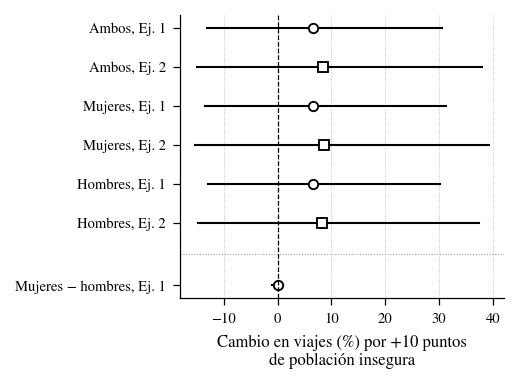

In [20]:

# Un renglón por modelo. Círculo = Ejercicio 1, cuadrado = Ejercicio 2.
# El último renglón (separado) es la diferencia mujeres − hombres: % de cambio
# en la razón de viajes F/M, no en los viajes.
filas = tabla.copy()
filas["etiqueta"] = filas["grupo"] + ", " + filas["ejercicio"]
y = np.arange(len(filas), dtype=float)
y[-1] += 0.6   # separa la fila de la diferencia

fig, ax = plt.subplots(figsize=(ANCHO_1COL, 2.6))
for yi, f in zip(y, filas.itertuples()):
    mk = "o" if f.ejercicio == "Ej. 1" else "s"
    ax.plot([f.pct_lo, f.pct_hi], [yi, yi], color="black", linewidth=1.0)
    ax.plot(f.pct, yi, marker=mk, markersize=4.5, color="black",
            markerfacecolor="white", markeredgewidth=0.9, linestyle="none")
ax.axvline(0, color="black", linestyle="--", linewidth=0.6)
ax.axhline((y[-2] + y[-1]) / 2, color="0.6", linewidth=0.5, linestyle=":")
ax.set_yticks(y)
ax.set_yticklabels(filas["etiqueta"])
ax.invert_yaxis()
ax.set_xlabel(f"Cambio en viajes (%) por +{DELTA_PP} puntos\nde población insegura")
ax.grid(axis="x", linestyle=":", linewidth=0.4, color="0.7")
fig.tight_layout()
guardar(fig, "figA_coeficientes_modelos")
plt.show()




En los seis modelos el coeficiente estimado es positivo (≈ +7 % a +9 % en viajes por cada 10 puntos más de población insegura), lo contrario al signo esperado. Sin embargo, ninguno es distinguible de cero: todos los intervalos al 95 % incluyen el cero (p ≈ 0.43–0.47 con t de 5 gl). No hay diferencia entre mujeres y hombres (diferencia ≈ 0, p = 0.91).

Que la asociación no sea significativa no implica que no exista. Con el modelo principal, los datos permiten descartar reducciones mayores a ~13 % en viajes por cada 10 puntos, pero solo se detectarían asociaciones de alrededor de 2.8 % por punto (≈ 28 % por 10 puntos) con 80 % de potencia.

                  variante    coef     ee  gl   ic_lo  ic_hi      p   n     pct   pct_lo  pct_hi
   Modelo completo (Ej. 1)  0.0064 0.0079   5 -0.0140 0.0267 0.4567 105  6.5874 -13.0271 30.6255
         Sin Benito Juárez  0.0131 0.0101   4 -0.0150 0.0412 0.2643  81 14.0319 -13.9049 51.0338
            Sin Cuauhtémoc  0.0091 0.0100   4 -0.0188 0.0370 0.4177  81  9.4950 -17.1622 44.7305
        Sin Miguel Hidalgo  0.0077 0.0136   4 -0.0301 0.0454 0.6029  81  7.9714 -25.9844 57.5051
              Sin Coyoacán  0.0016 0.0065   4 -0.0165 0.0197 0.8215  92  1.5810 -15.2226 21.7153
        Sin Álvaro Obregón  0.0087 0.0083   4 -0.0144 0.0319 0.3545  95  9.1097 -13.4287 37.5158
          Sin Azcapotzalco  0.0005 0.0053   4 -0.0142 0.0153 0.9244  95  0.5379 -13.2480 16.5145
            Sin estaciones  0.0018 0.0070   5 -0.0163 0.0199 0.8077 105  1.8204 -15.0113 21.9857
       Con log(estaciones) -0.0035 0.0043   5 -0.0145 0.0074 0.4470 105 -3.4567 -13.4810  7.7290
Solo 3 alcaldías completas -0.

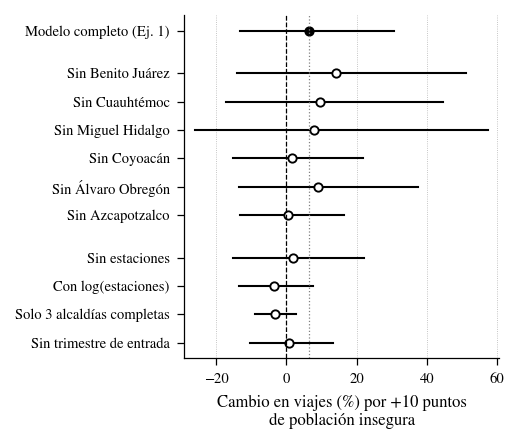

In [21]:
# [Celda 5] Fig. B: robustez del Ejercicio 1 agregado (N-5) ----------------
# Compara signos, tamaños e intervalos, no cuántas son significativas.
# Cada IC usa t con G-1 grados de libertad, así que las variantes con menos
# alcaldías tienen intervalos más anchos (con 3 alcaldías, gl = 2).
inicio = pa["periodo"].min()
entrada = pa.groupby("alcaldia_norm")["periodo"].transform("min")
es_entrada = (pa["periodo"] == entrada) & (entrada > inicio)
completas = [a for a in ORDEN if pa.loc[pa["alcaldia_norm"] == a, "periodo"].min() == inicio]

variantes = [("Modelo completo (Ej. 1)", pa, VARS_EJ1)]
variantes += [(f"Sin {NOMBRES[a]}", pa[pa["alcaldia_norm"] != a], VARS_EJ1) for a in ORDEN]
variantes += [
    ("Sin estaciones", pa, ["inseguro_pct"]),
    ("Con log(estaciones)", pa, ["inseguro_pct", "log_estaciones"]),
    ("Solo 3 alcaldías completas", pa[pa["alcaldia_norm"].isin(completas)], VARS_EJ1),
    ("Sin trimestre de entrada", pa[~es_entrada], VARS_EJ1),
]
rob = []
for nombre, datos, variables in variantes:
    r = resumen(correr_modelo_fe(datos, variables))
    r["variante"] = nombre
    rob.append(r)
rob = pd.DataFrame(rob)
print(rob[["variante", "coef", "ee", "gl", "ic_lo", "ic_hi", "p", "n",
           "pct", "pct_lo", "pct_hi"]].round(4).to_string(index=False))
rob.round(4).to_csv(os.path.join(CARPETA_FIGS, "tabla_robustez.csv"),
                    index=False, encoding="utf-8-sig")

# Separadores entre bloques: completo | quitar una alcaldía | otras variantes
y = np.arange(len(rob), dtype=float)
y[1:] += 0.5
y[1 + len(ORDEN):] += 0.5

# Límite del eje: los IC muy anchos se recortan y se marcan con una flecha
LIM = 60
fig, ax = plt.subplots(figsize=(ANCHO_1COL, 3.0))
for yi, f in zip(y, rob.itertuples()):
    lo, hi = max(f.pct_lo, -LIM), min(f.pct_hi, LIM)
    ax.plot([lo, hi], [yi, yi], color="black", linewidth=1.0)
    if f.pct_lo < -LIM:
        ax.plot(-LIM, yi, marker="<", color="black", markersize=3.5)
    if f.pct_hi > LIM:
        ax.plot(LIM, yi, marker=">", color="black", markersize=3.5)
    ax.plot(f.pct, yi, marker="o", markersize=4, color="black",
            markerfacecolor="black" if yi == 0 else "white", markeredgewidth=0.9)
ax.axvline(0, color="black", linestyle="--", linewidth=0.6)
ax.axvline(rob.loc[0, "pct"], color="0.5", linestyle=":", linewidth=0.6)
ax.set_xlim(max(rob["pct_lo"].min(), -LIM) - 3, min(rob["pct_hi"].max(), LIM) + 3)
ax.set_yticks(y)
ax.set_yticklabels(rob["variante"])
ax.invert_yaxis()
ax.set_xlabel(f"Cambio en viajes (%) por +{DELTA_PP} puntos\nde población insegura")
ax.grid(axis="x", linestyle=":", linewidth=0.4, color="0.7")
fig.tight_layout()
guardar(fig, "figB_robustez")
plt.show()

El signo del coeficiente no es estable entre especificaciones. Se vuelve negativo al usar log(estaciones) (−3.5 %) o al restringir la muestra a las tres alcaldías presentes desde el inicio (−3.2 %), y casi desaparece al excluir el trimestre de entrada de las alcaldías nuevas (+0.8 %) o al omitir las estaciones (+1.8 %). Esto sugiere que la estimación positiva del modelo principal depende de pocos trimestres de entrada y de la forma funcional de las estaciones. En todas las variantes el intervalo incluye el cero, por lo que la conclusión central se mantiene: no hay evidencia de asociación entre la percepción de inseguridad y el uso de ECOBICI.

Guardada: /content/drive/MyDrive/Tesis_caso/figuras_eda/figC_relacion_parcial.png/.pdf/.svg


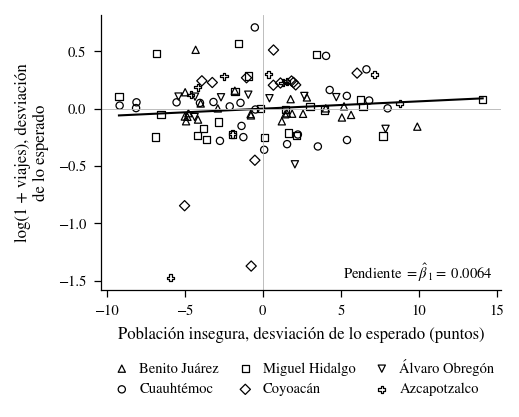

Pendiente FWL = 0.0064 (debe coincidir con β1 de Ambos, Ej. 1)
Desv. est. de % inseguro: cruda 16.5 pp; tras efectos fijos y estaciones 4.5 pp


In [22]:
#  [Celda 6] Fig. C: relación parcial (la variación que usa β1) ------------
# Residuos de log(1+viajes) y de % inseguro tras quitar efectos de alcaldía,
# de trimestre y estaciones activas (Frisch-Waugh-Lovell). La pendiente es
# exactamente el β1 del Ejercicio 1 agregado. Es descriptiva: no trae IC.



base = pa.dropna(subset=["log_viajes"] + VARS_EJ1).copy()
res_fwl = residualizar(base, ["inseguro_pct", "log_viajes"],
                       controles=["estaciones_activas"])
base["x_res"], base["y_res"] = res_fwl["inseguro_pct"], res_fwl["log_viajes"]
pend = np.polyfit(base["x_res"], base["y_res"], 1)[0]

fig, ax = plt.subplots(figsize=(ANCHO_1COL, 2.9))
for alc in ORDEN:
    sub = base[base["alcaldia_norm"] == alc]
    ax.scatter(sub["x_res"], sub["y_res"], s=12, facecolors="none",
               edgecolors="black", linewidths=0.6,
               marker=ESTILO_ALC[alc]["marker"], label=NOMBRES[alc])
xs = np.linspace(base["x_res"].min(), base["x_res"].max(), 50)
ax.plot(xs, pend * xs, color="black", linewidth=1.0)
ax.axhline(0, color="0.7", linewidth=0.4)
ax.axvline(0, color="0.7", linewidth=0.4)
ax.text(0.98, 0.04, rf"Pendiente $=\hat\beta_1=$ {pend:.4f}",
        transform=ax.transAxes, fontsize=7, ha="right")
ax.set_xlabel("Población insegura, desviación de lo esperado (puntos)")
ax.set_ylabel("log(1 + viajes), desviación\nde lo esperado")
ax.legend(ncol=3, frameon=False, loc="upper center",
          bbox_to_anchor=(0.5, -0.2), handletextpad=0.2, columnspacing=0.8)
fig.tight_layout()
guardar(fig, "figC_relacion_parcial")
plt.show()

print(f"Pendiente FWL = {pend:.4f} (debe coincidir con β1 de Ambos, Ej. 1)")
print(f"Desv. est. de % inseguro: cruda {base['inseguro_pct'].std():.1f} pp; "
      f"tras efectos fijos y estaciones {base['x_res'].std():.1f} pp")


